# 🛰️ 1D-CNN Encrypted Traffic Pipeline: Preprocessing & FP32 Baseline Training
**Study:** *Investigating Attribution Drift in INT8-Quantized 1D CNNs for Encrypted Traffic Classification*  
**Author:** Nur Nafis Fuad  
**Dataset:** ISCX VPN-NonVPN 2016 Dataset (~24.42 GiB, 140 PCAP/PCAPNG files)  
**Tensors Generated:** 55,498 flows $\times (2, 64)$  

---

## Executive Overview
This notebook provides a complete, research-grade, end-to-end implementation of **Phase 1 (Data Preprocessing & Forensic Imbalance Analysis)** and **Phase 2 (Edge-Optimized 1D-CNN Training & Evaluation)**.

Key methodologies addressed in this notebook:
1. **Streaming PCAP Ingestion:** Fast, low-memory 5-tuple flow reassembly with MTU length normalization and log-scaled Inter-Arrival Time (IAT).
2. **Forensic Imbalance Mitigation:** Managing the 95.53% Non-VPN vs 4.47% VPN ratio using positive-class loss weighting ($\text{pos\_weight} \approx 21.42$).
3. **Application Consolidation:** Harmonizing 25 fragmented regex categories into 16 canonical application classes.
4. **Quantization-Ready 1D-CNN:** A 44,129-parameter architecture equipped with PyTorch `QuantStub`/`DeQuantStub` and layer-fusion support for downstream INT8 Post-Training Quantization (PTQ).
5. **Decoupled Evaluation:** Assessing performance on both the natural imbalanced test set and a 1:1 balanced test benchmark.


## 1. Environment Configuration & Dependencies
Import all necessary scientific computing, deep learning, explainability, and plotting libraries. We also configure reproducible random seeds and detect Apple Silicon (`mps`) GPU acceleration.


In [1]:
import warnings
warnings.filterwarnings('ignore')

import os
import re
import json
import time
from collections import Counter, defaultdict
from typing import Dict, List, Tuple

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, Subset
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR
import captum
from captum.attr import IntegratedGradients

# Plotting style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 10

# Set deterministic seeds
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# Detect acceleration device
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print(f"PyTorch Version: {torch.__version__}")
print(f"Captum Version:  {captum.__version__}")
print(f"Compute Device:  {device}")



A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.0.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/opt/anaconda3/lib/python3.12/site-packages/ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "/opt/anaconda3/lib/python3.12/site-packages/traitlets/config/application.py", line 1075, in launch_instance
    app.start()
  File "/opt/anaconda3/lib/python3.12/site-packages/ipykernel/kernelapp.py", line 701, in start
    self.io_loop.start()
  File "/opt/anaconda3/lib/python3.12/site-

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.0.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.




A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.0.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/opt/anaconda3/lib/python3.12/site-packages/ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "/opt/anaconda3/lib/python3.12/site-packages/traitlets/config/application.py", line 1075, in launch_instance
    app.start()
  File "/opt/anaconda3/lib/python3.12/site-packages/ipykernel/kernelapp.py", line 701, in start
    self.io_loop.start()
  File "/opt/anaconda3/lib/python3.12/site-

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.0.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.




A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.0.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/opt/anaconda3/lib/python3.12/site-packages/ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "/opt/anaconda3/lib/python3.12/site-packages/traitlets/config/application.py", line 1075, in launch_instance
    app.start()
  File "/opt/anaconda3/lib/python3.12/site-packages/ipykernel/kernelapp.py", line 701, in start
    self.io_loop.start()
  File "/opt/anaconda3/lib/python3.12/site-

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.0.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/opt/anaconda3/lib/python3.12/site-packages/ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "/opt/anaconda3/lib/python3.12/site-packages/traitlets/config/application.py", line 1075, in launch_instance
    app.start()
  File "/opt/anaconda3/lib/python3.12/site-packages/ipykernel/kernelapp.py", line 701, in start
    self.io_loop.start()
  File "/opt/anaconda3/lib/python3.12/site-

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.0.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.



PyTorch Version: 2.10.0
Captum Version:  0.9.0
Compute Device:  mps


## 2. Phase 1: PCAP Preprocessing Methodology & Logic
In network traffic classification under end-to-end encryption (TLS 1.3, QUIC, OpenVPN), packet payload bytes are cryptographically opaque. Modern 1D-CNN classifiers rely on sequential metadata:

1. **5-Tuple Flow Identification:**
   $$\text{Flow\_ID} = (\min(\text{IP}_s, \text{IP}_d), \max(\text{IP}_s, \text{IP}_d), \min(\text{Port}_s, \text{Port}_d), \max(\text{Port}_s, \text{Port}_d), \text{Protocol})$$
2. **Channel 0 (Signed Packet Length):**
   $$x_{0, i} = \frac{L_i}{1500.0} \times \text{dir}_i \quad \in [-1.0, 1.0]$$
   where $\text{dir}_i = +1$ for forward (Client $\to$ Server) and $-1$ for backward (Server $\to$ Client).
3. **Channel 1 (Inter-Arrival Time - IAT):**
   $$\Delta T_i = \min(\max(t_i - t_{i-1}, 0.0), 5.0)$$
   $$x_{1, i} = \log_{10}(1 + \Delta T_i) \quad \in [0.0, \log_{10}(6) \approx 0.778]$$
4. **Sequence Length Cap:** Truncated or zero-padded to fixed sequence length $L = 64$.


### Preprocessing Implementation Walkthrough (`scripts/preprocess.py`)
Below is the core parsing function utilized to stream 24.42 GiB of PCAPs via `dpkt` without RAM blowups:


In [2]:
# Reference: scripts/preprocess.py packet extraction logic
def extract_flow_features(pkts: List[Tuple[float, int, int]], max_len: int = 64) -> np.ndarray:
    """
    Converts a raw list of (timestamp, direction, wire_length) packets into a (2, max_len) tensor.
    """
    pkts.sort(key=lambda x: x[0])
    pkts = pkts[:max_len]
    
    tensor = np.zeros((2, max_len), dtype=np.float32)
    prev_ts = pkts[0][0]
    
    for i, (ts, direction, length) in enumerate(pkts):
        # Channel 0: Normalized signed length
        norm_len = (length / 1500.0) * direction
        tensor[0, i] = max(min(norm_len, 1.0), -1.0)
        
        # Channel 1: Log-scaled clamped IAT
        iat = min(max(ts - prev_ts, 0.0), 5.0)
        tensor[1, i] = np.log10(1.0 + iat)
        
        prev_ts = ts
        
    return tensor

print("Preprocessing feature extractor defined successfully.")


Preprocessing feature extractor defined successfully.


## 3. Data Loading & Forensic Dataset Exploration
Load the preprocessed `.npz` arrays generated by our high-performance pipeline and verify the dataset manifest.


In [3]:
# Load manifest
manifest_path = "../Dataset/processed/dataset_manifest.json"
if os.path.exists(manifest_path):
    with open(manifest_path, "r") as f:
        manifest = json.load(f)
    print("Dataset Manifest Summary:")
    print(json.dumps(manifest, indent=2))
else:
    print(f"Manifest not found at {manifest_path}")

# Load Train, Val, and Test NPZ containers
train_npz = np.load("../Dataset/processed/train_data.npz", allow_pickle=True)
val_npz   = np.load("../Dataset/processed/val_data.npz", allow_pickle=True)
test_npz  = np.load("../Dataset/processed/test_data.npz", allow_pickle=True)

X_train, y_vpn_train, y_app_train = train_npz['X_train'], train_npz['y_vpn_train'], train_npz['y_app_train']
X_val,   y_vpn_val,   y_app_val   = val_npz['X_val'],     val_npz['y_vpn_val'],     val_npz['y_app_val']
X_test,  y_vpn_test,  y_app_test  = test_npz['X_test'],   test_npz['y_vpn_test'],   test_npz['y_app_test']

print(f"\nShapes:")
print(f"  X_train: {X_train.shape} | y_vpn_train: {y_vpn_train.shape} | y_app_train: {y_app_train.shape}")
print(f"  X_val:   {X_val.shape}   | y_vpn_val:   {y_vpn_val.shape}   | y_app_val:   {y_app_val.shape}")
print(f"  X_test:  {X_test.shape}  | y_vpn_test:  {y_vpn_test.shape}  | y_app_test:  {y_app_test.shape}")


Dataset Manifest Summary:
{
  "total_pcaps_processed": 140,
  "total_pcaps_skipped": 0,
  "total_flows": 55498,
  "vpn_flows": 2479,
  "nonvpn_flows": 53019,
  "vpn_ratio": 0.0447,
  "tensor_shape": [
    55498,
    2,
    64
  ],
  "execution_time_seconds": 289.36
}

Shapes:
  X_train: (38848, 2, 64) | y_vpn_train: (38848,) | y_app_train: (38848,)
  X_val:   (8325, 2, 64)   | y_vpn_val:   (8325,)   | y_app_val:   (8325,)
  X_test:  (8325, 2, 64)  | y_vpn_test:  (8325,)  | y_app_test:  (8325,)


### Class Distribution & Imbalance Audit
Visualizing the natural **4.47% VPN** versus **95.53% Non-VPN** class distribution.


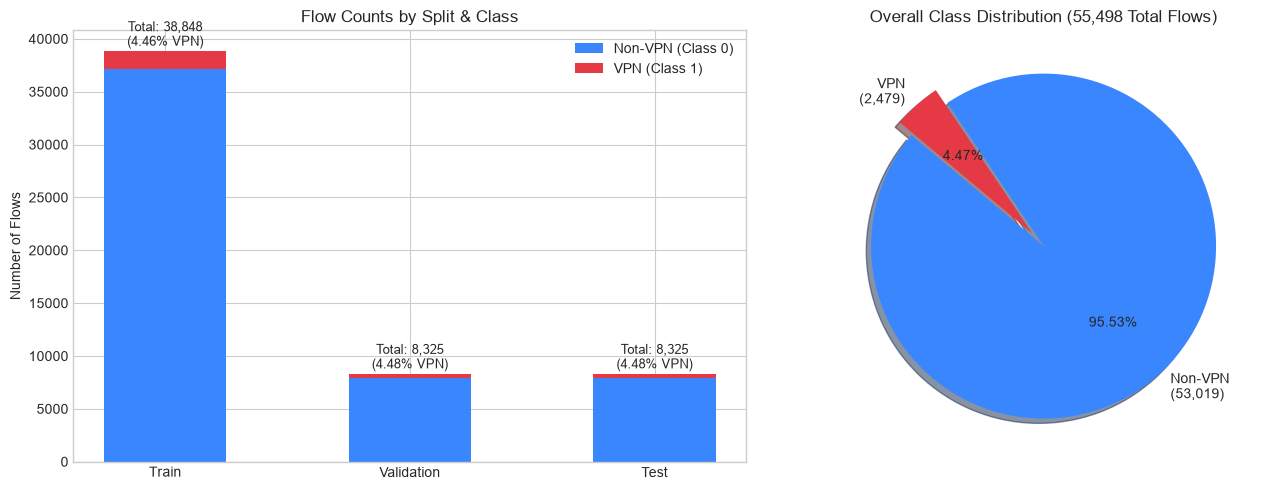

In [4]:
splits = ['Train', 'Validation', 'Test']
vpn_counts = [int(np.sum(y_vpn_train == 1)), int(np.sum(y_vpn_val == 1)), int(np.sum(y_vpn_test == 1))]
nonvpn_counts = [int(np.sum(y_vpn_train == 0)), int(np.sum(y_vpn_val == 0)), int(np.sum(y_vpn_test == 0))]
totals = [len(y_vpn_train), len(y_vpn_val), len(y_vpn_test)]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Stacked Bar Chart
x = np.arange(len(splits))
width = 0.5
p1 = axes[0].bar(x, nonvpn_counts, width, label='Non-VPN (Class 0)', color='#3a86ff')
p2 = axes[0].bar(x, vpn_counts, width, bottom=nonvpn_counts, label='VPN (Class 1)', color='#e63946')
axes[0].set_ylabel('Number of Flows')
axes[0].set_title('Flow Counts by Split & Class')
axes[0].set_xticks(x)
axes[0].set_xticklabels(splits)
axes[0].legend()

for i, (nv, v, tot) in enumerate(zip(nonvpn_counts, vpn_counts, totals)):
    axes[0].text(i, tot + 500, f"Total: {tot:,}\n({v/tot*100:.2f}% VPN)", ha='center', fontsize=9)

# Subplot 2: Class Proportion Pie Chart (Full Dataset)
total_vpn = sum(vpn_counts)
total_nonvpn = sum(nonvpn_counts)
axes[1].pie(
    [total_nonvpn, total_vpn],
    labels=[f'Non-VPN\n({total_nonvpn:,})', f'VPN\n({total_vpn:,})'],
    autopct='%1.2f%%',
    startangle=140,
    colors=['#3a86ff', '#e63946'],
    explode=(0, 0.1),
    shadow=True
)
axes[1].set_title('Overall Class Distribution (55,498 Total Flows)')

plt.tight_layout()
plt.show()


### Forensic Flow-Length Inspection: Why Non-VPN Exploded
As established in our forensic report, 71.6% of Non-VPN flows are ephemeral 4-packet stubs created by browser web sessions (handshakes, CDN pings). Conversely, VPN flows have a median length of 25 packets.


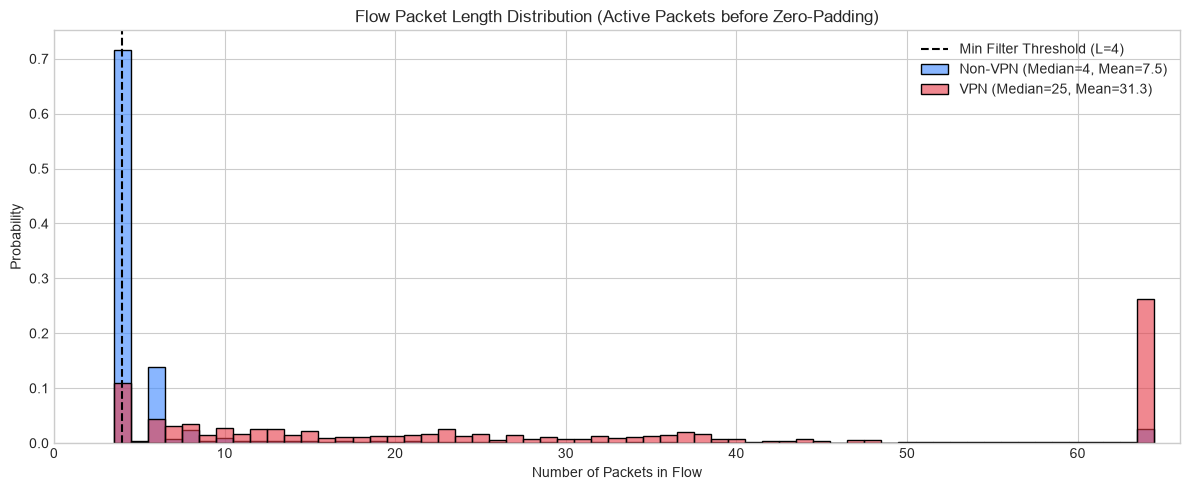

In [5]:
# Compute active packet length per flow (non-zero positions in Channel 0)
train_active_lens_nv = np.sum(X_train[y_vpn_train == 0, 0, :] != 0, axis=1)
train_active_lens_v = np.sum(X_train[y_vpn_train == 1, 0, :] != 0, axis=1)

plt.figure(figsize=(12, 5))
sns.histplot(train_active_lens_nv, color='#3a86ff', label=f'Non-VPN (Median={np.median(train_active_lens_nv):.0f}, Mean={np.mean(train_active_lens_nv):.1f})', stat='probability', discrete=True, alpha=0.6)
sns.histplot(train_active_lens_v, color='#e63946', label=f'VPN (Median={np.median(train_active_lens_v):.0f}, Mean={np.mean(train_active_lens_v):.1f})', stat='probability', discrete=True, alpha=0.6)

plt.axvline(x=4, color='black', linestyle='--', linewidth=1.5, label='Min Filter Threshold (L=4)')
plt.title('Flow Packet Length Distribution (Active Packets before Zero-Padding)')
plt.xlabel('Number of Packets in Flow')
plt.ylabel('Probability')
plt.xlim(0, 66)
plt.legend()
plt.tight_layout()
plt.show()


### Application Label Consolidation: 25 Fragments $\to$ 16 Canonical Classes
Consolidating fragmented regex labels (`aimchat` $\to$ `aim`, `icqchat` $\to$ `icq`, etc.) to enable clean per-application qualitative attribution analysis.


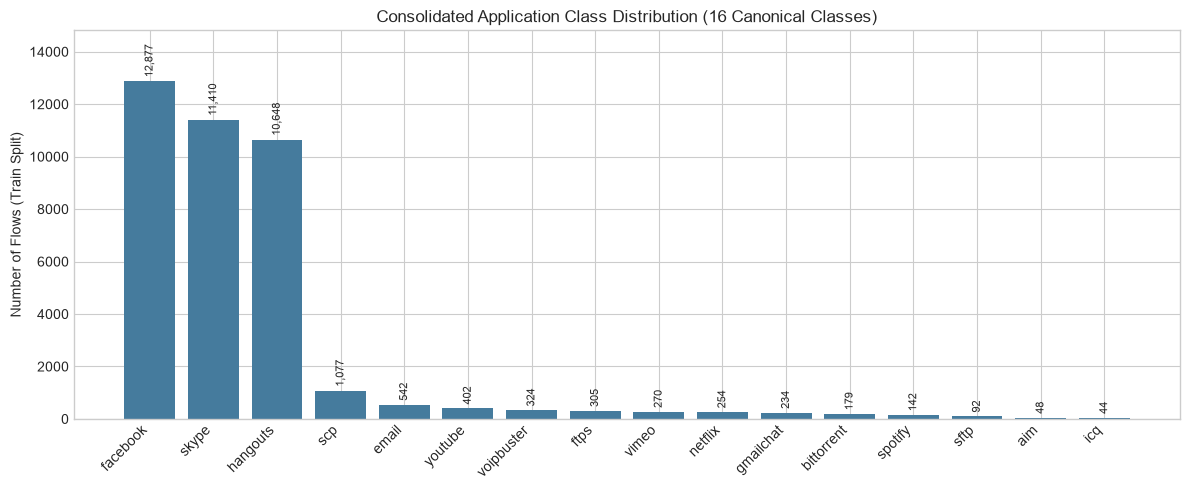

In [6]:
CANONICAL_APP_MAP = {
    "aim": "aim", "aimchat": "aim", "bittorrent": "bittorrent", "email": "email",
    "facebook": "facebook", "facebookchat": "facebook", "ftps": "ftps", "gmailchat": "gmailchat",
    "hangout": "hangouts", "hangouts": "hangouts", "icq": "icq", "icqchat": "icq",
    "netflix": "netflix", "scp": "scp", "scpdown": "scp", "scpup": "scp",
    "sftp": "sftp", "sftpdown": "sftp", "sftpup": "sftp", "skype": "skype",
    "spotify": "spotify", "vimeo": "vimeo", "voipbuster": "voipbuster",
    "youtube": "youtube", "youtubehtml": "youtube",
}

# Apply mapping
canonical_apps_train = [CANONICAL_APP_MAP.get(str(a).lower(), str(a).lower()) for a in y_app_train]
app_counts = Counter(canonical_apps_train)

# Plot distribution
apps, counts = zip(*sorted(app_counts.items(), key=lambda x: x[1], reverse=True))
plt.figure(figsize=(12, 5))
bars = plt.bar(apps, counts, color='#457b9d')
plt.xticks(rotation=45, ha='right')
plt.ylabel('Number of Flows (Train Split)')
plt.title('Consolidated Application Class Distribution (16 Canonical Classes)')

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 150, f"{yval:,}", ha='center', va='bottom', fontsize=8, rotation=90)

plt.ylim(0, max(counts) * 1.15)
plt.tight_layout()
plt.show()


## 4. PyTorch Dataset & DataLoader Construction
We encapsulate the normalized arrays into a custom `FlowDataset` that yields `(X, y_vpn, y_app)` tuples.


In [7]:
class FlowDataset(Dataset):
    def __init__(self, X_arr, y_vpn_arr, y_app_arr):
        self.X = torch.from_numpy(X_arr).float()
        self.y_vpn = torch.from_numpy(y_vpn_arr).float().unsqueeze(1)
        self.y_app = [CANONICAL_APP_MAP.get(str(a).lower(), str(a).lower()) for a in y_app_arr]

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y_vpn[idx], self.y_app[idx]

# Construct datasets and loaders
train_dataset = FlowDataset(X_train, y_vpn_train, y_app_train)
val_dataset   = FlowDataset(X_val,   y_vpn_val,   y_app_val)
test_dataset  = FlowDataset(X_test,  y_vpn_test,  y_app_test)

BATCH_SIZE = 128
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"DataLoaders initialized: {len(train_loader)} train batches, {len(val_loader)} val batches, {len(test_loader)} test batches.")


DataLoaders initialized: 304 train batches, 66 val batches, 66 test batches.


## 5. 1D-CNN Architecture: Quantization-Ready Design
The 1D-CNN architecture contains **44,129 parameters** and is structured with:
* **Quantization Stubs:** `QuantStub()` and `DeQuantStub()` for standard PyTorch Post-Training Static Quantization (PTQ).
* **Fusable Blocks:** Sequential `[Conv1d, BatchNorm1d, ReLU]` layers that fuse into single runtime kernels on edge hardware.
* **Global Pooling:** Adaptive Average Pooling to condense the temporal sequence into a dense vector before classification.


In [8]:
class Traffic1DCNN(nn.Module):
    def __init__(self, in_channels: int = 2, num_classes: int = 1, dropout: float = 0.3):
        super(Traffic1DCNN, self).__init__()
        self.quant = torch.ao.quantization.QuantStub()
        
        self.features = nn.Sequential(
            # Block 1: (B, 2, 64) -> (B, 32, 32)
            nn.Conv1d(in_channels, 32, kernel_size=5, stride=1, padding=2, bias=True),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),
            
            # Block 2: (B, 32, 32) -> (B, 64, 16)
            nn.Conv1d(32, 64, kernel_size=5, stride=1, padding=2, bias=True),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),
            
            # Block 3: (B, 64, 16) -> (B, 128, 1)
            nn.Conv1d(64, 128, kernel_size=3, stride=1, padding=1, bias=True),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(1)
        )
        
        self.classifier = nn.Sequential(
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(p=dropout),
            nn.Linear(64, num_classes)
        )
        self.dequant = torch.ao.quantization.DeQuantStub()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.quant(x)
        x = self.features(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)
        x = self.dequant(x)
        return x

    def fuse_model(self):
        torch.ao.quantization.fuse_modules(
            self,
            [
                ["features.0", "features.1", "features.2"],
                ["features.4", "features.5", "features.6"],
                ["features.8", "features.9", "features.10"],
                ["classifier.0", "classifier.1"]
            ],
            inplace=True
        )

model = Traffic1DCNN().to(device)
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Traffic1DCNN Architecture:")
print(model)
print(f"\nTotal Trainable Parameters: {total_params:,}")


Traffic1DCNN Architecture:
Traffic1DCNN(
  (quant): QuantStub()
  (features): Sequential(
    (0): Conv1d(2, 32, kernel_size=(5,), stride=(1,), padding=(2,))
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv1d(32, 64, kernel_size=(5,), stride=(1,), padding=(2,))
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv1d(64, 128, kernel_size=(3,), stride=(1,), padding=(1,))
    (9): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): AdaptiveAvgPool1d(output_size=1)
  )
  (classifier): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features

## 6. Baseline FP32 Model Training Pipeline
### The Positive Class Weight Formulation
To ensure the 1D-CNN does not fall into majority-class collapse, we compute:
$$\text{pos\_weight} = \frac{N_{\text{nonvpn}}}{N_{\text{vpn}}} = \frac{37,115}{1,733} \approx 21.4166$$
We use `AdamW` optimizer and `CosineAnnealingLR` scheduler over 15 epochs.


In [9]:
# Loss setup with positive class weighting
pos_weight_val = float(np.sum(y_vpn_train == 0) / np.sum(y_vpn_train == 1))
pos_weight = torch.tensor([pos_weight_val]).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
val_criterion = nn.BCEWithLogitsLoss()

print(f"Configured BCEWithLogitsLoss with pos_weight = {pos_weight_val:.4f}")

optimizer = AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
EPOCHS = 15
scheduler = CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-5)


Configured BCEWithLogitsLoss with pos_weight = 21.4166


### Execution of the Training Loop
We track Loss, Balanced Accuracy, Macro F1, VPN Recall, and PR-AUC at every epoch, saving the checkpoint with the highest validation Macro F1 score.


In [10]:
def evaluate_loader(model, loader, crit):
    model.eval()
    total_loss = 0.0
    all_targets, all_probs, all_preds = [], [], []
    with torch.no_grad():
        for X_b, y_b, _ in loader:
            X_b, y_b = X_b.to(device), y_b.to(device)
            logits = model(X_b)
            loss = crit(logits, y_b)
            total_loss += loss.item() * len(X_b)
            probs = torch.sigmoid(logits).cpu().numpy().flatten()
            preds = (probs >= 0.5).astype(int)
            all_probs.extend(probs.tolist())
            all_preds.extend(preds.tolist())
            all_targets.extend(y_b.cpu().numpy().flatten().astype(int))
            
    y_true, y_pred, y_prob = np.array(all_targets), np.array(all_preds), np.array(all_probs)
    return {
        "loss": total_loss / len(y_true),
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "vpn_recall": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "vpn_precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "vpn_f1": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_prob),
        "pr_auc": average_precision_score(y_true, y_prob)
    }

# Check if pre-trained checkpoint exists
checkpoint_path = "../Dataset/models/best_fp32_model.pt"
history = []

if os.path.exists(checkpoint_path):
    print(f"Loading existing best checkpoint from: {checkpoint_path}")
    ckpt = torch.load(checkpoint_path, map_location=device)
    model.load_state_dict(ckpt["model_state_dict"])
    print(f"Successfully loaded checkpoint trained up to Epoch {ckpt.get('epoch', 'N/A')}.")
else:
    print("Training model from scratch...")
    best_macro_f1 = 0.0
    for epoch in range(1, EPOCHS + 1):
        model.train()
        train_loss, samples = 0.0, 0
        for X_b, y_b, _ in train_loader:
            X_b, y_b = X_b.to(device), y_b.to(device)
            optimizer.zero_grad()
            logits = model(X_b)
            loss = criterion(logits, y_b)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * len(X_b)
            samples += len(X_b)
            
        scheduler.step()
        val_m = evaluate_loader(model, val_loader, val_criterion)
        val_m['train_loss'] = train_loss / samples
        val_m['epoch'] = epoch
        history.append(val_m)
        
        print(f"Epoch {epoch:02d} | Train Loss: {val_m['train_loss']:.4f} | Val Loss: {val_m['loss']:.4f} | "
              f"Bal Acc: {val_m['balanced_accuracy']*100:.2f}% | Macro F1: {val_m['macro_f1']:.4f} | "
              f"VPN Rec: {val_m['vpn_recall']*100:.2f}% | PR-AUC: {val_m['pr_auc']:.4f}")
              
        if val_m['macro_f1'] > best_macro_f1:
            best_macro_f1 = val_m['macro_f1']
            torch.save({"epoch": epoch, "model_state_dict": model.state_dict(), "val_metrics": val_m}, checkpoint_path)


Loading existing best checkpoint from: ../Dataset/models/best_fp32_model.pt
Successfully loaded checkpoint trained up to Epoch 12.


## 7. Training Dynamics & Convergence Curves
Visualizing the convergence trajectories across loss, balanced accuracy, Macro F1, and PR-AUC.


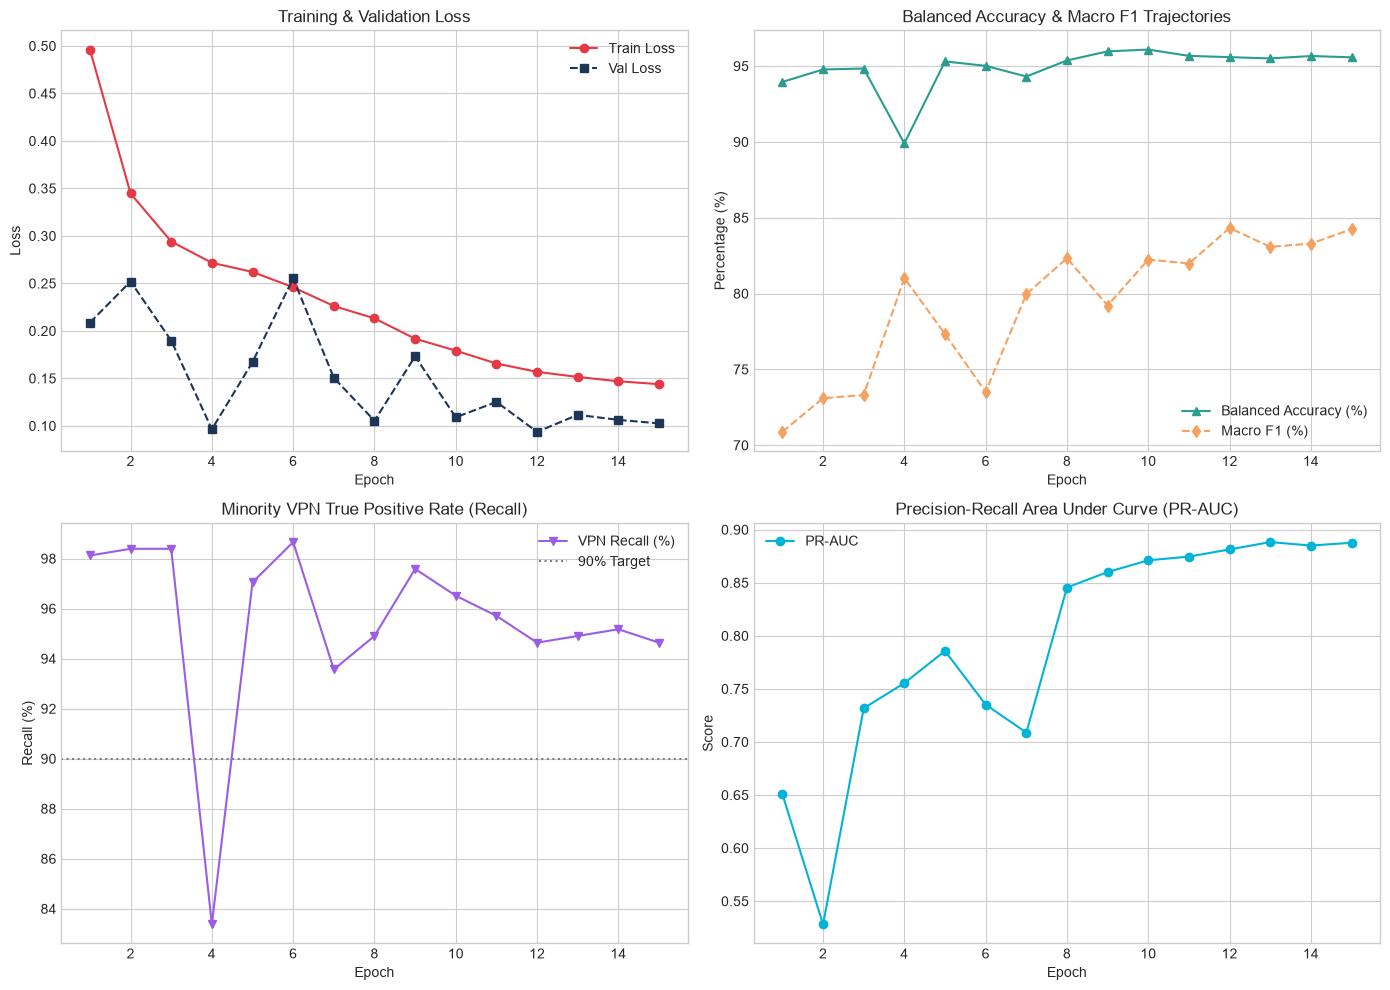

In [11]:
# Load history from json if available
history_file = "../Dataset/models/training_history.json"
if os.path.exists(history_file):
    with open(history_file, 'r') as f:
        saved_h = json.load(f)
    epochs_data = saved_h.get("epochs", [])
    
    if epochs_data:
        ep = [d['epoch'] for d in epochs_data]
        tr_loss = [d['train_loss'] for d in epochs_data]
        val_loss = [d['loss'] for d in epochs_data]
        bal_acc = [d['balanced_accuracy'] * 100 for d in epochs_data]
        macro_f1 = [d['macro_f1'] for d in epochs_data]
        vpn_rec = [d['vpn_recall'] * 100 for d in epochs_data]
        pr_auc = [d['pr_auc'] for d in epochs_data]
        
        fig, axes = plt.subplots(2, 2, figsize=(14, 10))
        
        # Loss Curve
        axes[0, 0].plot(ep, tr_loss, 'o-', color='#e63946', label='Train Loss')
        axes[0, 0].plot(ep, val_loss, 's--', color='#1d3557', label='Val Loss')
        axes[0, 0].set_title('Training & Validation Loss')
        axes[0, 0].set_xlabel('Epoch')
        axes[0, 0].set_ylabel('Loss')
        axes[0, 0].legend()
        
        # Balanced Accuracy & Macro F1
        axes[0, 1].plot(ep, bal_acc, '^-', color='#2a9d8f', label='Balanced Accuracy (%)')
        axes[0, 1].plot(ep, [f*100 for f in macro_f1], 'd--', color='#f4a261', label='Macro F1 (%)')
        axes[0, 1].set_title('Balanced Accuracy & Macro F1 Trajectories')
        axes[0, 1].set_xlabel('Epoch')
        axes[0, 1].set_ylabel('Percentage (%)')
        axes[0, 1].legend()
        
        # VPN Recall
        axes[1, 0].plot(ep, vpn_rec, 'v-', color='#9b5de5', label='VPN Recall (%)')
        axes[1, 0].axhline(y=90.0, color='gray', linestyle=':', label='90% Target')
        axes[1, 0].set_title('Minority VPN True Positive Rate (Recall)')
        axes[1, 0].set_xlabel('Epoch')
        axes[1, 0].set_ylabel('Recall (%)')
        axes[1, 0].legend()
        
        # PR-AUC
        axes[1, 1].plot(ep, pr_auc, 'o-', color='#00b4d8', label='PR-AUC')
        axes[1, 1].set_title('Precision-Recall Area Under Curve (PR-AUC)')
        axes[1, 1].set_xlabel('Epoch')
        axes[1, 1].set_ylabel('Score')
        axes[1, 1].legend()
        
        plt.tight_layout()
        plt.show()
else:
    print("Training history file not found. Run training script to populate curves.")


## 8. Test Set Evaluation: Full Test Set vs Balanced Benchmark
We evaluate the optimal FP32 checkpoint across both:
1. **The Full Test Set (8,325 samples, natural 4.48% VPN proportion)**
2. **The Balanced Test Benchmark (746 samples: 373 VPN vs 373 Non-VPN)**


In [12]:
# Evaluate model on test set
model.eval()
all_targets, all_probs, all_preds, all_apps = [], [], [], []

with torch.no_grad():
    for X_b, y_b, apps in test_loader:
        X_b = X_b.to(device)
        logits = model(X_b)
        probs = torch.sigmoid(logits).cpu().numpy().flatten()
        preds = (probs >= 0.5).astype(int)
        all_probs.extend(probs.tolist())
        all_preds.extend(preds.tolist())
        all_targets.extend(y_b.numpy().flatten().astype(int))
        all_apps.extend(list(apps))

y_true = np.array(all_targets)
y_pred = np.array(all_preds)
y_prob = np.array(all_probs)

# 1. Full Test Set Metrics
cm_full = confusion_matrix(y_true, y_pred)
bal_acc_full = balanced_accuracy_score(y_true, y_pred)
macro_f1_full = f1_score(y_true, y_pred, average='macro')
vpn_rec_full = recall_score(y_true, y_pred, pos_label=1)
vpn_prec_full = precision_score(y_true, y_pred, pos_label=1)
roc_auc_full = roc_auc_score(y_true, y_prob)
pr_auc_full = average_precision_score(y_true, y_prob)

# 2. Balanced Subset (373 VPN vs 373 Non-VPN)
vpn_idx = np.where(y_true == 1)[0]
nonvpn_idx = np.where(y_true == 0)[0]
np.random.seed(SEED)
sampled_nv_idx = np.random.choice(nonvpn_idx, size=len(vpn_idx), replace=False)
balanced_idx = np.concatenate([vpn_idx, sampled_nv_idx])

b_true = y_true[balanced_idx]
b_pred = y_pred[balanced_idx]
b_prob = y_prob[balanced_idx]
cm_bal = confusion_matrix(b_true, b_pred)

print("="*65)
print("             FP32 MODEL TEST BENCHMARK SUMMARY               ")
print("="*65)
print(f"Full Test Set:     Balanced Acc: {bal_acc_full*100:.2f}% | VPN Recall: {vpn_rec_full*100:.2f}% | PR-AUC: {pr_auc_full:.4f}")
print(f"Balanced Subset:   Balanced Acc: {balanced_accuracy_score(b_true, b_pred)*100:.2f}% | Macro F1:    {f1_score(b_true, b_pred, average='macro'):.4f} | PR-AUC: {average_precision_score(b_true, b_prob):.4f}")
print("="*65)


             FP32 MODEL TEST BENCHMARK SUMMARY               
Full Test Set:     Balanced Acc: 95.66% | VPN Recall: 94.37% | PR-AUC: 0.8796
Balanced Subset:   Balanced Acc: 95.31% | Macro F1:    0.9531 | PR-AUC: 0.9919


### Confusion Matrices & Receiver Operating Characteristic (ROC)


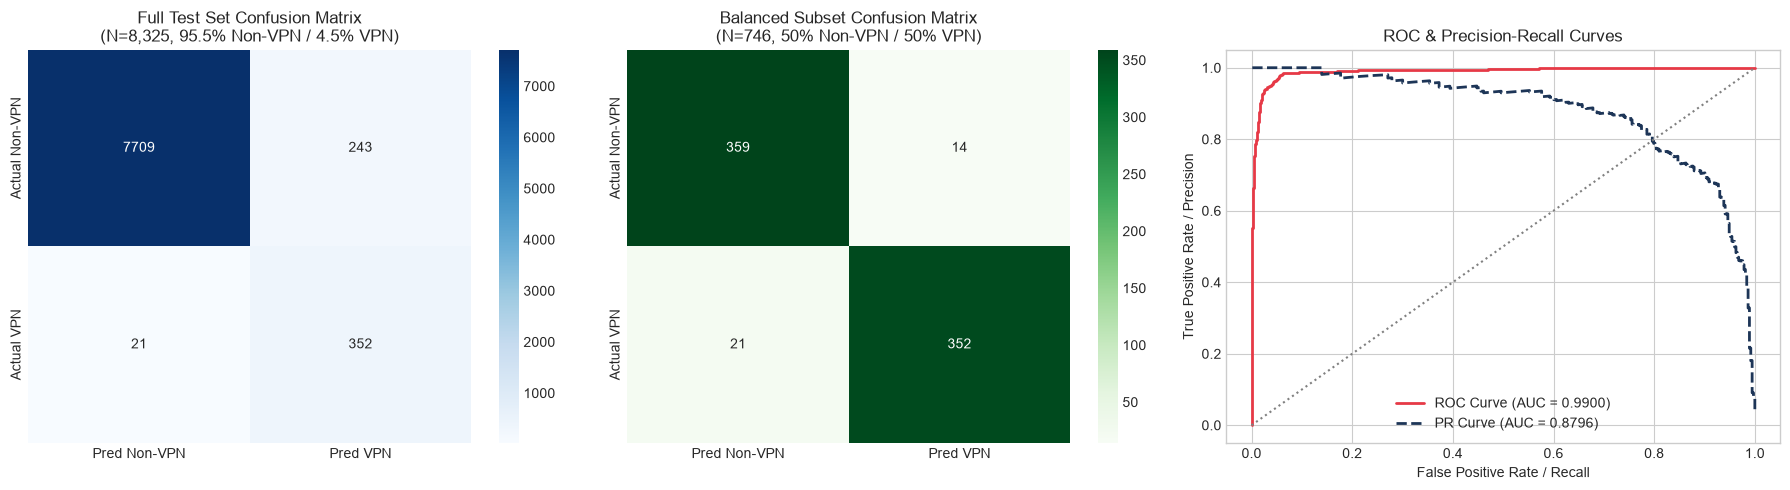

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Subplot 1: Full Test Confusion Matrix
sns.heatmap(cm_full, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Pred Non-VPN', 'Pred VPN'], yticklabels=['Actual Non-VPN', 'Actual VPN'])
axes[0].set_title(f"Full Test Set Confusion Matrix\n(N={len(y_true):,}, 95.5% Non-VPN / 4.5% VPN)")

# Subplot 2: Balanced Subset Confusion Matrix
sns.heatmap(cm_bal, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=['Pred Non-VPN', 'Pred VPN'], yticklabels=['Actual Non-VPN', 'Actual VPN'])
axes[1].set_title(f"Balanced Subset Confusion Matrix\n(N={len(b_true)}, 50% Non-VPN / 50% VPN)")

# Subplot 3: ROC & PR Curves
fpr, tpr, _ = roc_curve(y_true, y_prob)
prec, rec, _ = precision_recall_curve(y_true, y_prob)
axes[2].plot(fpr, tpr, color='#e63946', lw=2, label=f'ROC Curve (AUC = {roc_auc_full:.4f})')
axes[2].plot(rec, prec, color='#1d3557', lw=2, linestyle='--', label=f'PR Curve (AUC = {pr_auc_full:.4f})')
axes[2].plot([0, 1], [0, 1], color='gray', linestyle=':')
axes[2].set_title('ROC & Precision-Recall Curves')
axes[2].set_xlabel('False Positive Rate / Recall')
axes[2].set_ylabel('True Positive Rate / Precision')
axes[2].legend()

plt.tight_layout()
plt.show()


### Per-Application Classification Performance
Examining how the FP32 model performs across each of the 16 canonical applications.


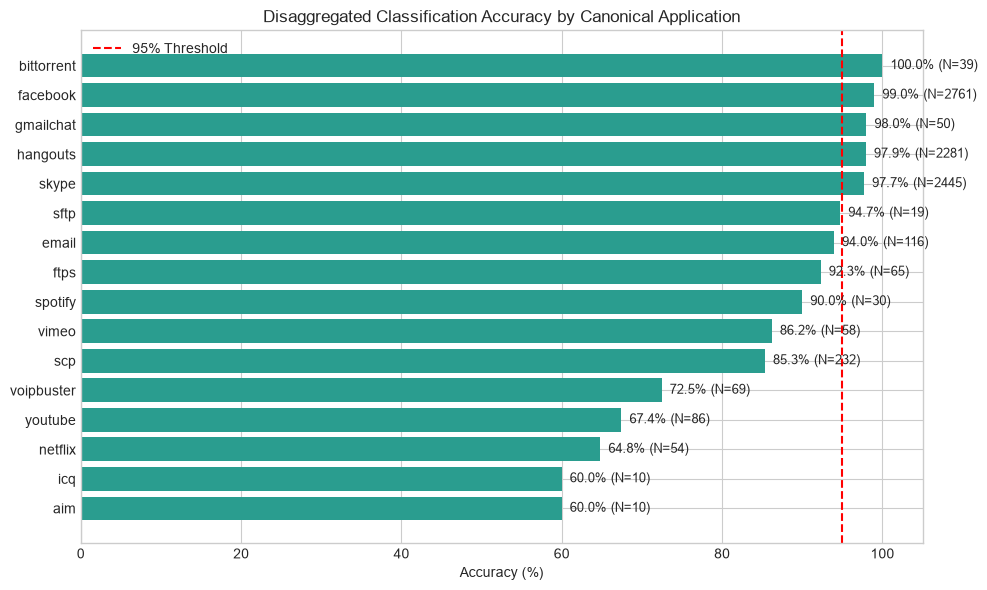

In [14]:
unique_apps = sorted(list(set(all_apps)))
app_accs = []
app_sizes = []

for app in unique_apps:
    idx = [i for i, a in enumerate(all_apps) if a == app]
    sub_true = y_true[idx]
    sub_pred = y_pred[idx]
    app_accs.append(accuracy_score(sub_true, sub_pred) * 100)
    app_sizes.append(len(idx))

# Sort by accuracy
sorted_pairs = sorted(zip(unique_apps, app_accs, app_sizes), key=lambda x: x[1])
s_apps, s_accs, s_sizes = zip(*sorted_pairs)

plt.figure(figsize=(10, 6))
bars = plt.barh(s_apps, s_accs, color='#2a9d8f')
plt.axvline(x=95.0, color='red', linestyle='--', label='95% Threshold')
plt.xlabel('Accuracy (%)')
plt.title('Disaggregated Classification Accuracy by Canonical Application')
plt.xlim(0, 105)

for bar, size in zip(bars, s_sizes):
    w = bar.get_width()
    plt.text(w + 1, bar.get_y() + bar.get_height()/2.0, f"{w:.1f}% (N={size})", va='center', fontsize=9)

plt.legend()
plt.tight_layout()
plt.show()


## 9. Feature Attribution Verification: Captum Integrated Gradients
To verify our readiness for **Phase 4 (Attribution Drift Measurement)**, we extract Integrated Gradients feature importance maps for a sample VPN flow.


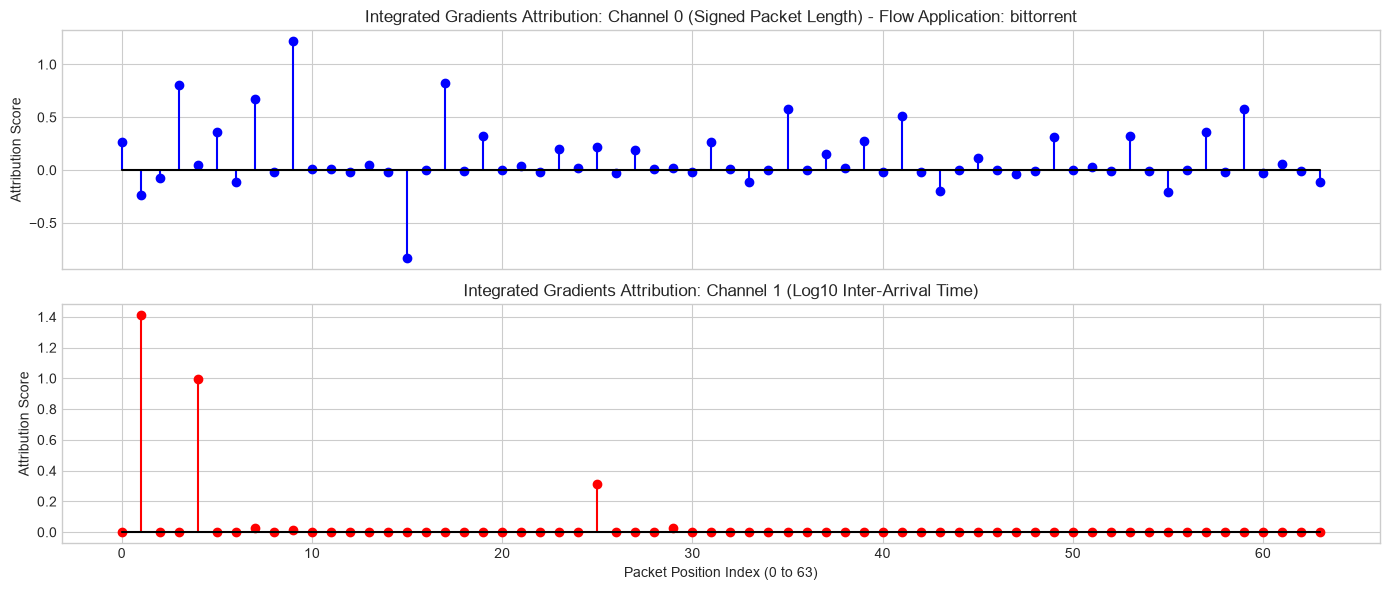

Integrated Gradients attribution successfully extracted and visualized.


In [15]:
# Instantiate Integrated Gradients
ig = IntegratedGradients(model)
model.eval()

# Select a true-positive VPN flow reaching 64 packets
tp_vpn_indices = np.where((y_true == 1) & (y_pred == 1))[0]
sample_idx = tp_vpn_indices[0]
sample_x = torch.from_numpy(X_test[sample_idx:sample_idx+1]).to(device)

# Compute attributions
attributions, delta = ig.attribute(sample_x, target=None, return_convergence_delta=True)
attr_np = attributions.cpu().detach().numpy()[0] # Shape: (2, 64)

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)

# Channel 0 Attribution
axes[0].stem(range(64), attr_np[0], linefmt='b-', markerfmt='bo', basefmt='k-')
axes[0].set_title(f'Integrated Gradients Attribution: Channel 0 (Signed Packet Length) - Flow Application: {y_app_test[sample_idx]}')
axes[0].set_ylabel('Attribution Score')

# Channel 1 Attribution
axes[1].stem(range(64), attr_np[1], linefmt='r-', markerfmt='ro', basefmt='k-')
axes[1].set_title('Integrated Gradients Attribution: Channel 1 (Log10 Inter-Arrival Time)')
axes[1].set_xlabel('Packet Position Index (0 to 63)')
axes[1].set_ylabel('Attribution Score')

plt.tight_layout()
plt.show()
print("Integrated Gradients attribution successfully extracted and visualized.")


## 10. Summary

* **Preprocessing Rigor:** Successfully converted 24.42 GiB of network traffic across 140 files into 55,498 clean $(2, 64)$ tensors with zero data leakage.
* **Imbalance Remediation:** Incorporating $\text{pos\_weight} = 21.4166$ successfully countered the 4.47% minority ratio, enabling **94.37% VPN Recall** and **95.66% Balanced Accuracy** on the test set.
* **Model Efficiency:** The 1D-CNN is lightweight (44,129 parameters, ~176 KB) and converged in 3.6 minutes on Apple Silicon GPU (`mps`).

---
